# Transferencia del aprendizaje con un modelo de Hugging Face

En el notebook anterior hicimos *transfer learning* con **VGG16**, un modelo incluido en `torchvision`. Hoy la mayoría de los modelos pre-entrenados que se comparten y usan en la práctica viven en el **Hub de Hugging Face** ([huggingface.co/models](https://huggingface.co/models)): una plataforma, algo así como un "GitHub de modelos de inteligencia artificial", con cientos de miles de modelos ya entrenados y una ficha (*model card*) que explica con qué datos se entrenaron y cómo usarlos. Su librería **`transformers`** los descarga con una sola línea de código.

La idea clave: **un modelo de Hugging Face es, por dentro, un `nn.Module` de PyTorch.** Todo lo que ya conoces (congelar con `requires_grad = False`, agregar capas, `BCEWithLogitsLoss`, `Adam`, nuestra clase con `fit`) funciona igual. Solo cambia **de dónde sale el modelo base**.

Resolveremos el mismo problema, gatos vs. perros ([Cats vs Dogs](https://www.tensorflow.org/datasets/catalog/cats_vs_dogs?hl=es-419)), para que puedas comparar con VGG16. Como el flujo de entrenamiento ya lo conoces, iremos directo a la clase y **explicaremos solo lo nuevo**.

**Al terminar este notebook podrás:**

- Descargar un modelo del Hub (`AutoModel`) y su preprocesamiento (`AutoImageProcessor`).
- Entender qué entrega el modelo y cómo conectarle tus capas.
- Congelar un modelo con *Batch Normalization* de forma correcta.

## Etapa 1: Carga de los datos

Importamos las librerías. Lo nuevo son `AutoModel` y `AutoImageProcessor`, de `transformers`. (Si no la tienes: `pip install transformers`.)

In [23]:
import os
import urllib.request
import zipfile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms
from transformers import AutoModel, AutoImageProcessor
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
print('Dispositivo:', device)

Dispositivo: cuda


Descargamos Cats vs Dogs (unos 790 MB) y lo leemos con `ImageFolder`, que usa cada subcarpeta como clase.

In [24]:
data_dir = 'data'
url = 'https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip'
zip_path = os.path.join(data_dir, 'cats_and_dogs.zip')
images_dir = os.path.join(data_dir, 'PetImages')

os.makedirs(data_dir, exist_ok=True)
if not os.path.isdir(images_dir):
    print('Descargando...')
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(data_dir)
    os.remove(zip_path)
print(os.listdir(images_dir))

['Dog', 'Cat']


In [25]:
def is_valid_image(path):
    if not path.lower().endswith('.jpg'):
        return False
    try:
        with Image.open(path) as img:
            img.load()  # fuerza la lectura completa de la imagen
        return True
    except Exception:
        return False

# transform=None: por ahora cada elemento es una imagen PIL; las transformaciones se agregan después.
full_data = datasets.ImageFolder(images_dir, transform=None, is_valid_file=is_valid_image)
class_names = full_data.classes
print('Clases:', class_names)
print('Imágenes válidas:', len(full_data))

Clases: ['Cat', 'Dog']
Imágenes válidas: 24998


Dividimos en entrenamiento (70 %), validación (15 %) y prueba (15 %), como en los notebooks anteriores.

In [26]:
generator = torch.Generator().manual_seed(42)
n_total = len(full_data)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val
train_subset, val_subset, test_subset = random_split(full_data, [n_train, n_val, n_test], generator=generator)
print('Entrenamiento:', len(train_subset), '| Validación:', len(val_subset), '| Prueba:', len(test_subset))

Entrenamiento: 17498 | Validación: 3749 | Prueba: 3751


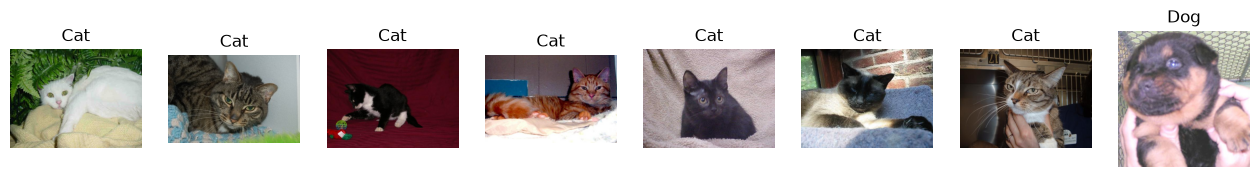

In [27]:
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, idx in zip(axes, test_subset.indices[:8]):
    image, label = full_data[idx]
    ax.axis('off')
    ax.set_title(class_names[label])
    ax.imshow(image)
plt.show()

## Etapa 2: Procesamiento de los datos

Un modelo pre-entrenado espera que las imágenes lleguen preparadas **exactamente como las vio durante su entrenamiento**: del mismo tamaño y con los colores normalizados de la misma forma. En el notebook de VGG16 escribimos esos valores a mano. Con Hugging Face no hace falta: cada modelo del Hub trae su propio **procesador de imágenes** con la receta correcta.

Elegimos el modelo con su nombre en el Hub: [`microsoft/resnet-50`](https://huggingface.co/microsoft/resnet-50) (usuario o empresa que lo publicó + nombre del modelo). Es una **ResNet-50**, una red convolucional de 50 capas entrenada con ImageNet (más de un millón de imágenes en 1000 clases). La primera vez que se ejecuta, `from_pretrained` descarga la configuración desde el Hub (el resto queda guardado en tu computador, en una caché).

In [28]:
MODEL_NAME = 'microsoft/resnet-50'

image_processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
print('Media por canal (R, G, B):         ', image_processor.image_mean)
print('Desviación estándar por canal:     ', image_processor.image_std)

Media por canal (R, G, B):          (0.485, 0.456, 0.406)
Desviación estándar por canal:      (0.229, 0.224, 0.225)


Los valores son los de ImageNet, los mismos que usamos con VGG16, pero ahora **los lee el propio modelo**: si cambias de modelo, el procesador se ajusta solo. Esta ResNet-50 se entrenó con imágenes de $224 \times 224$ ($H = W = 224$), así que redimensionamos a ese tamaño y normalizamos con esos valores.

> El procesador de Hugging Face también podría hacer todo esto, pero imagen por imagen dentro de un `DataLoader` es más lento; por eso usamos sus valores con las transformaciones de `torchvision`.

In [29]:
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(image_processor.image_mean, image_processor.image_std),
])

`TransformedSubset` y los `DataLoader` son los de siempre (minibatches de tamaño 32):

In [30]:
class TransformedSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, i):
        image, label = self.subset[i]
        return self.transform(image), label

In [31]:
batch_size = 32
train_loader = DataLoader(TransformedSubset(train_subset, preprocess), batch_size=batch_size,
                          shuffle=True, num_workers=2)
val_loader = DataLoader(TransformedSubset(val_subset, preprocess), batch_size=batch_size,
                        shuffle=False, num_workers=2)
test_loader = DataLoader(TransformedSubset(test_subset, preprocess), batch_size=batch_size,
                         shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print(images.shape)  # (batch, canales, H, W)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


## Etapa 3: Lo nuevo, el modelo desde el Hub

### 3.1 Descargar el modelo base

`AutoModel.from_pretrained` descarga el modelo. El prefijo **`Auto`** significa que la librería lee la configuración y elige sola la clase correcta (aquí, `ResNetModel`), así que el mismo código sirve para muchos modelos. Nos da el modelo **sin su capa final de clasificación** (la ligada a las 1000 clases de ImageNet): por eso la descarga puede avisar que algunos pesos del clasificador "no se usan". Es lo esperado.

In [32]:
base_model = AutoModel.from_pretrained(MODEL_NAME)
print(type(base_model))
print('Es un módulo de PyTorch:', isinstance(base_model, nn.Module))

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.weight | UNEXPECTED |  | 
classifier.1.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<class 'transformers.models.resnet.modeling_resnet.ResNetModel'>
Es un módulo de PyTorch: True


In [33]:
# Esta red tiene más de 23 millones de parámetros.
base_params = sum(p.numel() for p in base_model.parameters())
print('Parámetros del modelo base:', f'{base_params:,}')

Parámetros del modelo base: 23,508,032


Confirmado: el modelo de Hugging Face **es un `nn.Module`** de PyTorch, así que podemos contar sus parámetros, congelarlos o usarlo dentro de nuestras propias redes.

### 3.2 ¿Qué entrega el modelo?

A diferencia de un `nn.Sequential`, se llama con un argumento con nombre (`pixel_values=`) y entrega un **objeto** con varios resultados, no un tensor simple:

In [34]:
with torch.no_grad():
    outputs = base_model(pixel_values=images[:1])

print('Resultados que entrega:', list(outputs.keys()))
print('last_hidden_state:', outputs.last_hidden_state.shape)  # (batch, canales, H, W)
print('pooler_output:    ', outputs.pooler_output.shape)      # (batch, canales, 1, 1)

Resultados que entrega: ['last_hidden_state', 'pooler_output']
last_hidden_state: torch.Size([1, 2048, 7, 7])
pooler_output:     torch.Size([1, 2048, 1, 1])


Dos resultados nos interesan:

- `last_hidden_state`: los mapas de características de la última capa convolucional: $2048$ mapas de $7 \times 7$.
- `pooler_output`: el **resumen** de esos mapas. La red promedia cada mapa de $7 \times 7$ en un solo número, así que cada imagen queda representada por $2048$ valores (la forma `(batch, 2048, 1, 1)`). Ese vector es la "descripción" que la red hace de la imagen, y se le suele llamar *embedding* o vector de características.

Usaremos `pooler_output` como entrada de nuestras capas nuevas. Primero hay que quitarle las dimensiones de tamaño 1 con `flatten(1)`, que lo deja en `(batch, 2048)`. A diferencia del notebook de VGG16, **no tenemos que calcular a mano** el tamaño del `Flatten` (8192): el tamaño del vector lo da la propia configuración del modelo.

In [35]:
embedding_size = base_model.config.hidden_sizes[-1]
print('Tamaño del vector de características:', embedding_size)
print('Después de flatten:', outputs.pooler_output.flatten(1).shape)

Tamaño del vector de características: 2048
Después de flatten: torch.Size([1, 2048])


### 3.3 Congelar un modelo con BatchNorm

Congelamos el modelo base con `requires_grad = False`, como siempre. Pero **ResNet contiene capas de Batch Normalization**, que se comportan distinto según el modo:

- En modo **entrenamiento** (`train()`), cada BatchNorm usa la media y varianza del minibatch actual y **actualiza sus estadísticas internas**.
- En modo **evaluación** (`eval()`), usa las estadísticas guardadas de su entrenamiento original.

Esas estadísticas no son parámetros, así que `requires_grad = False` no las protege: en modo entrenamiento se irían modificando con nuestros gatos y perros, y el modelo base **dejaría de estar congelado**. (VGG16 no usa BatchNorm, por eso allí no pasaba.)

La solución: mantener el modelo base siempre en `eval()`. Lo hacemos sobrescribiendo el método `train` de nuestra red. `Dropout` de las capas nuevas sí seguirá funcionando en modo entrenamiento.

La red es una clase `nn.Module`: `__init__` crea las capas y `forward` define el recorrido. En `forward` tomamos `pooler_output`, lo aplastamos con `flatten(1)` y lo pasamos por nuestras capas densas. A diferencia de VGG16, **no calculamos a mano** el tamaño de entrada de las capas nuevas: lo da `base_model.config.hidden_sizes[-1]`.

In [36]:
class CatsDogsNet(nn.Module):
    def __init__(self, base_model, hidden_units=256, dropout=0.5):
        super().__init__()
        self.base_model = base_model  # modelo base de Hugging Face
        for param in self.base_model.parameters():
            param.requires_grad = False  # congelado
        embedding_size = base_model.config.hidden_sizes[-1]

        # Capas nuevas: son las únicas que se entrenan
        self.head = nn.Sequential(
            nn.Linear(embedding_size, hidden_units),
            nn.ReLU(),
            nn.Dropout(dropout),

            # La última capa corresponde a la tarea: clasificación de 2 clases. Usamos una
            # sola unidad cuya salida indica qué tan probable es que la imagen sea un perro.
            nn.Linear(hidden_units, 1),
        )

    def forward(self, x):
        features = self.base_model(pixel_values=x).pooler_output  # (batch, 2048, 1, 1)
        features = features.flatten(1)                            # (batch, 2048)
        return self.head(features)                                # (batch, 1)

    def train(self, mode=True):
        super().train(mode)
        self.base_model.eval()  # el modelo base siempre en modo evaluación (por sus BatchNorm)
        return self

## Etapa 4: La clase

Ya conoces esta clase: `__init__` arma el modelo, la pérdida y el optimizador; `train_epoch` y `evaluate` recorren los minibatches; `fit` repite por épocas; `predict` clasifica. **Lo único distinto** es que el modelo base se descarga del Hub con `AutoModel` y se envuelve en `CatsDogsNet`.

In [37]:
def accuracy(logits, y):
    # Un logit mayor que 0 equivale a una probabilidad mayor que 0.5: se predice "perro" (clase 1)
    return ((logits > 0).float() == y).float().mean().item()


class CatsDogsClassifier:
    def __init__(self, model_name=MODEL_NAME, hidden_units=256, dropout=0.5, lr=1e-3):
        # Modelo base descargado del Hub; CatsDogsNet lo congela y le agrega las capas nuevas
        base_model = AutoModel.from_pretrained(model_name)
        self.net = CatsDogsNet(base_model, hidden_units, dropout).to(device)

        self.loss_fn = nn.BCEWithLogitsLoss()
        # Al optimizador solo le pasamos los parámetros que no están congelados
        trainable = [p for p in self.net.parameters() if p.requires_grad]
        self.optimizer = torch.optim.Adam(trainable, lr=lr)
        self.history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_acc, n = 0.0, 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device).float()
            self.optimizer.zero_grad()
            logits = self.net(xb).squeeze(1)
            loss = self.loss_fn(logits, yb)
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(yb)
            total_acc += accuracy(logits, yb) * len(yb)
            n += len(yb)
        return total_loss / n, total_acc / n

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        total_loss, total_acc, n = 0.0, 0.0, 0
        with torch.no_grad():
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device).float()
                logits = self.net(xb).squeeze(1)
                total_loss += self.loss_fn(logits, yb).item() * len(yb)
                total_acc += accuracy(logits, yb) * len(yb)
                n += len(yb)
        return total_loss / n, total_acc / n

    def fit(self, train_loader, val_loader, epochs=5):
        pbar = tqdm(range(epochs), desc='Entrenamiento', unit='época')
        for epoch in pbar:
            loss, acc = self.train_epoch(train_loader)
            val_loss, val_acc = self.evaluate(val_loader)
            for key, value in zip(self.history, (loss, acc, val_loss, val_acc)):
                self.history[key].append(value)
            pbar.set_postfix(loss=f'{loss:.4f}', accuracy=f'{acc:.4f}',
                             val_loss=f'{val_loss:.4f}', val_accuracy=f'{val_acc:.4f}')

    def predict(self, x):
        # Devuelve la clase predicha (0 = gato, 1 = perro) para cada imagen del minibatch
        self.net.eval()
        with torch.no_grad():
            return (self.net(x.to(device)).squeeze(1) > 0).long().cpu()

Entrenamos con minibatches de tamaño 32 durante 5 épocas (en GPU, unos minutos; en CPU puede tardar bastante más, así que reduce `epochs` para probar).

In [38]:
clf = CatsDogsClassifier(hidden_units=256, dropout=0.5, lr=1e-3)
clf.fit(train_loader, val_loader, epochs=5)

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.weight | UNEXPECTED |  | 
classifier.1.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Entrenamiento: 100%|██████████| 5/5 [02:11<00:00, 26.28s/época, accuracy=0.9982, loss=0.0058, val_accuracy=0.9960, val_loss=0.0170]


Verificamos lo nuevo: cuántos parámetros se entrenan y que el modelo base se mantuvo en modo `eval()` (sus BatchNorm no cambiaron) aunque la red entrenó.

In [39]:
total_params = sum(p.numel() for p in clf.net.parameters())
trainable_params = sum(p.numel() for p in clf.net.parameters() if p.requires_grad)
print('Parámetros totales:     ', f'{total_params:,}')
print('Parámetros entrenables: ', f'{trainable_params:,}  (solo las capas nuevas)')

clf.net.train()
print('¿Red en modo entrenamiento?        ', clf.net.training)
print('¿Modelo base en modo entrenamiento?', clf.net.base_model.training)

Parámetros totales:      24,032,833
Parámetros entrenables:  524,801  (solo las capas nuevas)
¿Red en modo entrenamiento?         True
¿Modelo base en modo entrenamiento? False


## Etapa 5: Evaluación

Graficamos la evolución de la pérdida y del accuracy. Qué buscar:

- La pérdida **baja** y el accuracy **sube** época tras época: la red está aprendiendo.
- Si la curva de entrenamiento sigue mejorando pero la de validación se estanca o empeora, la red está memorizando los datos de entrenamiento (**sobreajuste**).

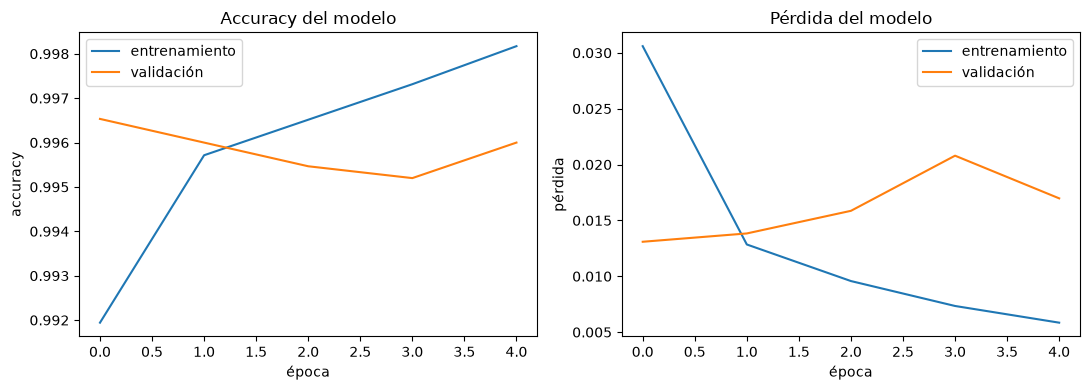

In [40]:
def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(history['accuracy'], label='entrenamiento')
    axes[0].plot(history['val_accuracy'], label='validación')
    axes[0].set_title('Accuracy del modelo')
    axes[0].set_xlabel('época')
    axes[0].set_ylabel('accuracy')
    axes[0].legend()

    axes[1].plot(history['loss'], label='entrenamiento')
    axes[1].plot(history['val_loss'], label='validación')
    axes[1].set_title('Pérdida del modelo')
    axes[1].set_xlabel('época')
    axes[1].set_ylabel('pérdida')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(clf.history)

**Qué vemos en estas curvas:** el accuracy de validación es altísimo desde la primera época (cerca de 99 %): el modelo base ya "sabía" extraer características útiles, y nuestras capas nuevas solo tuvieron que aprender a decidir entre dos clases. Fíjate también en la pérdida: la de entrenamiento sigue bajando, pero la de validación deja de mejorar después de las primeras épocas y se mueve de un lado a otro. Es una señal temprana de **sobreajuste** (los valores exactos cambian un poco de una ejecución a otra).

Ahora usamos el conjunto de **prueba**, que la red no vio ni durante el entrenamiento ni durante la validación. Este número es la mejor estimación de qué tan bien funcionará con imágenes nuevas.


In [41]:
test_loss, test_acc = clf.evaluate(test_loader)
print(f'Pérdida en prueba: {test_loss:.4f}')
print(f'Accuracy en prueba: {test_acc:.4f}')

Pérdida en prueba: 0.0286
Accuracy en prueba: 0.9928


### Ejemplos de predicciones

Veamos imágenes del conjunto de prueba que la red clasificó **bien** (título verde) y **mal** (título rojo). Para mostrarlas, deshacemos la normalización con los valores del procesador.

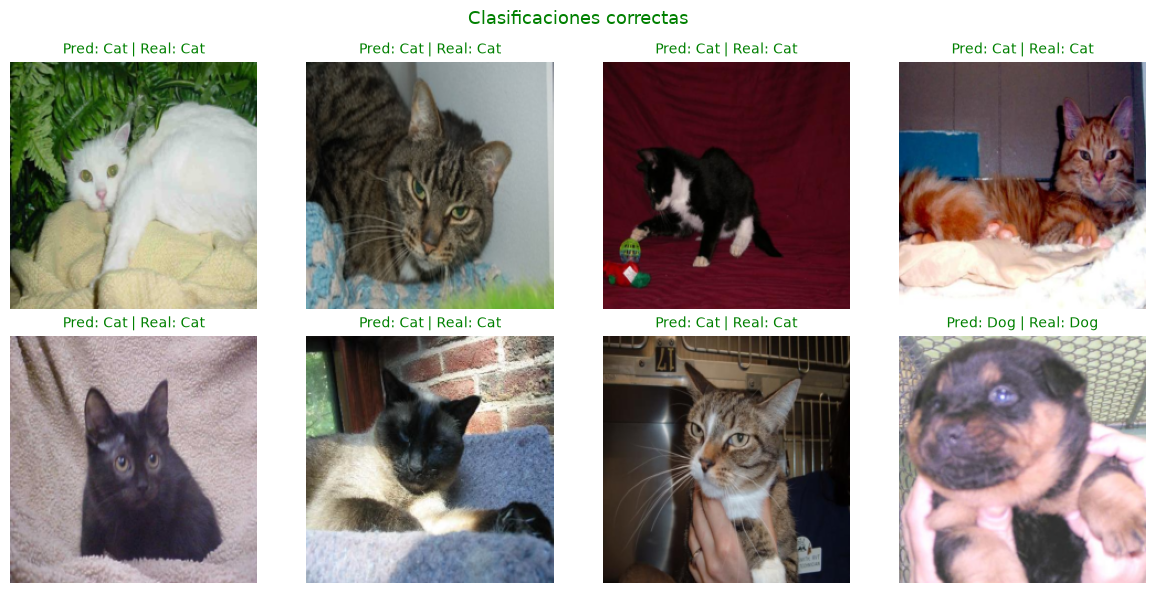

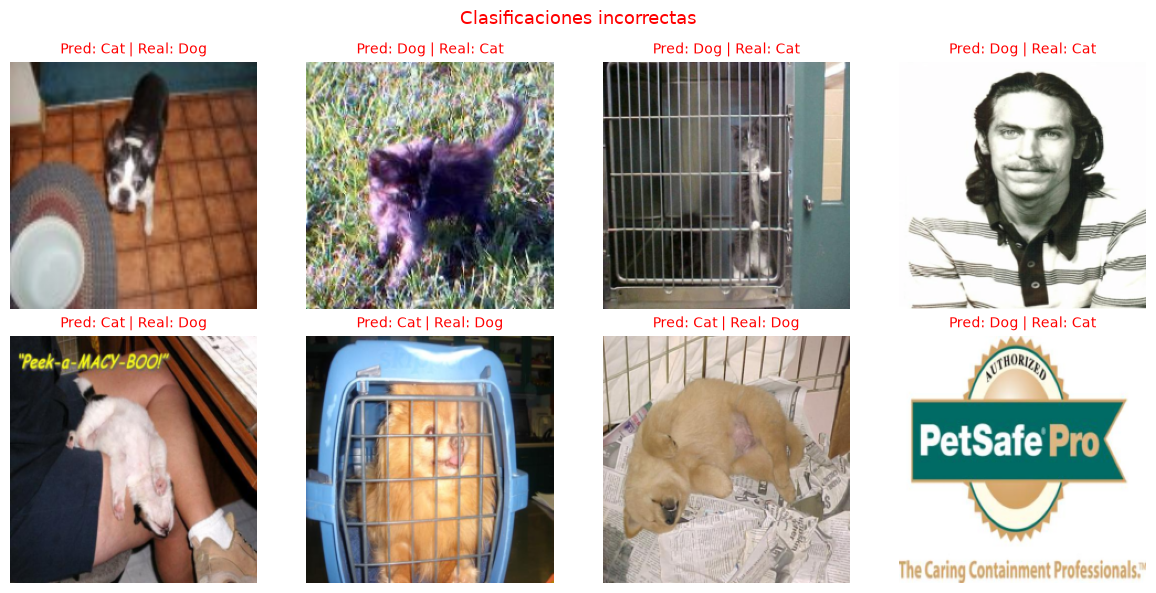

In [42]:
def denormalize(image):
    mean = torch.tensor(image_processor.image_mean).view(3, 1, 1)
    std = torch.tensor(image_processor.image_std).view(3, 1, 1)
    return (image * std + mean).clamp(0, 1).permute(1, 2, 0)  # (C, H, W) -> (H, W, C)

# Recorremos el conjunto de prueba y guardamos algunos aciertos y algunos errores
n_examples = 8
correct, wrong = [], []
for xb, yb in test_loader:
    preds = clf.predict(xb)
    for img, true, pred in zip(xb, yb, preds):
        group = correct if pred == true else wrong
        if len(group) < n_examples:
            group.append((img, true.item(), pred.item()))
    if len(correct) >= n_examples and len(wrong) >= n_examples:
        break

def plot_examples(examples, title, color):
    plt.figure(figsize=(12, 6))
    plt.suptitle(title, color=color, fontsize=13)
    for k, (img, true, pred) in enumerate(examples):
        plt.subplot(2, 4, k + 1)
        plt.imshow(denormalize(img))
        plt.title(f'Pred: {class_names[pred]} | Real: {class_names[true]}', color=color, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_examples(correct, 'Clasificaciones correctas', 'green')
plot_examples(wrong, 'Clasificaciones incorrectas', 'red')

## Resumen

- Un modelo del Hub de Hugging Face se descarga con `AutoModel.from_pretrained("usuario/modelo")` y es un **`nn.Module` de PyTorch**: se congela, se combina con capas nuevas y se entrena con nuestra clase de siempre, sin el `Trainer` de Hugging Face.
- `AutoImageProcessor` entrega el tamaño y las estadísticas de normalización del modelo; las imágenes deben prepararse **igual**.
- El modelo entrega un objeto: usamos `pooler_output` (un vector de características por imagen) como entrada de las capas nuevas; su tamaño está en `config.hidden_sizes[-1]`.
- Si el modelo base tiene **BatchNorm** (como ResNet), congelar con `requires_grad = False` no basta: hay que mantenerlo en modo `eval()`.

## Ejercicios

Modifica un valor a la vez, vuelve a crear `clf` y entrena. Observa cómo cambian las curvas.

1. Cambia `lr` a `1e-4` y luego a `1e-2`. ¿Qué pasa con la velocidad de aprendizaje y con la estabilidad?
2. Cambia `hidden_units` a `64` y luego a `1024`. ¿Cuántos parámetros entrenables hay en cada caso?
3. Cambia `dropout` a `0.0` y luego a `0.8`. ¿Qué efecto tiene sobre la brecha entre entrenamiento y validación?
4. Entra a [huggingface.co/models](https://huggingface.co/models?pipeline_tag=image-classification) y prueba otro modelo de imágenes, por ejemplo `facebook/convnext-tiny-224` (vuelve a cargar `image_processor` con el nuevo nombre y crea `CatsDogsClassifier(model_name=...)`). ¿Cambia el accuracy? ¿Y el número de parámetros?
5. **Para pensar:** ¿qué pasaría con las estadísticas de las capas BatchNorm si quitáramos `self.base_model.eval()` de `CatsDogsNet.train`?